# Enterprise Prompt Engineering Framework (Ollama)
## Prompt Strategies for Causal Discovery Analysis based on Telematics Vehicles dataset

The code provides implementation of prompt engineering strategies
utilizes LLMs models via Ollama API (localhost).

In [2]:
# =============
# CONFIGURATION
# =============
OLLAMA_URL = "http://localhost:11434/api/generate"
#MODEL_NAME = "gemma3:1b"  # I need to change manually
MODEL_NAME = "gemma:7b"  # I need to change manually
TEMPERATURE = 0.2
TOP_P = 0.9


In [ ]:
import requests

def call_ollama(prompt):
    payload = {
        "model": MODEL_NAME,
        "prompt": prompt,
        "stream": False,
        "temperature": TEMPERATURE,
        "top_p": TOP_P
    }
    response = requests.post(OLLAMA_URL, json=payload)
    return response.json()["response"]

hy


## Dataset Loading (based on CSV normalization dataset)


In [4]:
import pandas as pd

# ==============================
# LOAD DATASET FROM CSV
# ==============================
#file_path = "../../Caruso/inVehicle_N_RU043701_ignitionstatus_geolocation.csv"
file_path = "../normalized/01_Caruso_inVehicle_N_RU043701_Normalized_UC_Mercedes-Benz_Hybrid_Energy_Consumption_01.03.2025-30.04.2025.csv"

df = pd.read_csv(file_path)

# Required columns for causal analysis
required_columns = [
    'batteryvoltage',
    'sochighlevel',
    'energyconsumptionaverage',
    'electricremaining',
    'mileage',
    'speed_kmh',
    'acceleration_kmh2'
]

df = df[required_columns].dropna()
df


,batteryvoltage,sochighlevel,energyconsumptionaverage,electricremaining,mileage,speed_kmh,acceleration_kmh2
0,0.375940,1.00,0.981432,0.755725,0.0,0.0,0.669445
1,0.375940,1.00,0.981432,0.755725,0.0,0.0,0.669445
2,0.375940,1.00,0.981432,0.755725,0.0,0.0,0.669445
3,0.375940,1.00,0.981432,0.755725,0.0,0.0,0.669445
4,0.375940,1.00,0.981432,0.755725,0.0,0.0,0.669445
...,...,...,...,...,...,...,...
15721,0.218045,0.85,0.124668,0.778626,1.0,0.0,0.669445
15722,0.218045,0.85,0.124668,0.778626,1.0,0.0,0.669445
15723,0.218045,0.85,0.124668,0.778626,1.0,0.0,0.669445
15724,0.218045,0.85,0.124668,0.778626,1.0,0.0,0.669445


In [5]:
# Base Prompt

def base_prompt(df, required_columns):
    return f"""
Analyze the following dataset and determine causal discovery between features, looking at each historical data feature in detail.
No explanation. Only causal discovery. The relationship must be presented by "→" and the direction of causality must be clear. 
Only output the causal discovery without any explanation.

Use ONLY these exact feature names exactly as written:
batteryvoltage, sochighlevel, energyconsumptionaverage, electricremaining, mileage, speed_kmh, acceleration_kmh2.

Do not rename, capitalize differently, use spaces, or use synonyms.
Output only one relationship per line in this exact format:
feature1 -> feature2

Dataset: {df}
Features: {required_columns}

Remarks and short description of each feature:

batteryvoltage = Represents the voltage level of the vehicle's battery.
Affects power delivery to the motor and other electrical components.
Lower battery voltage may indicate battery degradation or low charge.

sochighlevel = State of Charge (SOC) High Level, measuring the battery's charge percentage.
A higher value means more available electric energy for vehicle operation.
Directly influences driving range and power efficiency.

energyconsumptionaverage = Represents the average amount of energy consumed over a certain distance or time.
Higher consumption suggests inefficient driving, battery aging, or external factors (speed, acceleration, terrain).
Key for range estimation and battery management.

electricremaining = The remaining electric energy available in the battery.
Determines how much further the vehicle can travel before requiring recharging.
Decreases with higher energy consumption and lower SOC.

mileage = The total distance traveled by the vehicle.
Affects battery wear and efficiency, as higher mileage may indicate battery degradation over time.
Important for vehicle maintenance and efficiency tracking.

speed_kmh = The current speed of the vehicle measured in kilometers per hour (km/h).
Impacts energy consumption, with higher speeds generally leading to higher consumption due to aerodynamic drag.

acceleration_kmh2 = The rate of change of speed measured in km/h².
Higher acceleration requires more power, leading to increased energy consumption.
Affects battery efficiency, driving dynamics, and motor performance.
"""


## Strategy 1: Zero-Shot Prompting


In [26]:
# Zero-Shot Prompting
prompt = base_prompt(df, required_columns)
result = call_ollama(prompt)
print(result)


batteryvoltage -> energyconsumptionaverage
batteryvoltage -> electricremaining
batteryvoltage -> speed_kmh
batteryvoltage -> acceleration_kmh2
sochighlevel -> energyconsumptionaverage
sochighlevel -> electricremaining
energyconsumptionaverage -> electricremaining
mileage -> speed_kmh
speed_kmh -> acceleration_kmh2


Adjacency Matrix:
                          batteryvoltage  sochighlevel  \
batteryvoltage                         0             0   
sochighlevel                           0             0   
energyconsumptionaverage               0             0   
electricremaining                      0             0   
mileage                                0             0   
speed_kmh                              0             0   
acceleration_kmh2                      0             0   

                          energyconsumptionaverage  electricremaining  \
batteryvoltage                                   1                  1   
sochighlevel                                     1                  1   
energyconsumptionaverage                         0                  1   
electricremaining                                0                  0   
mileage                                          0                  0   
speed_kmh                                        0                  0   
accele

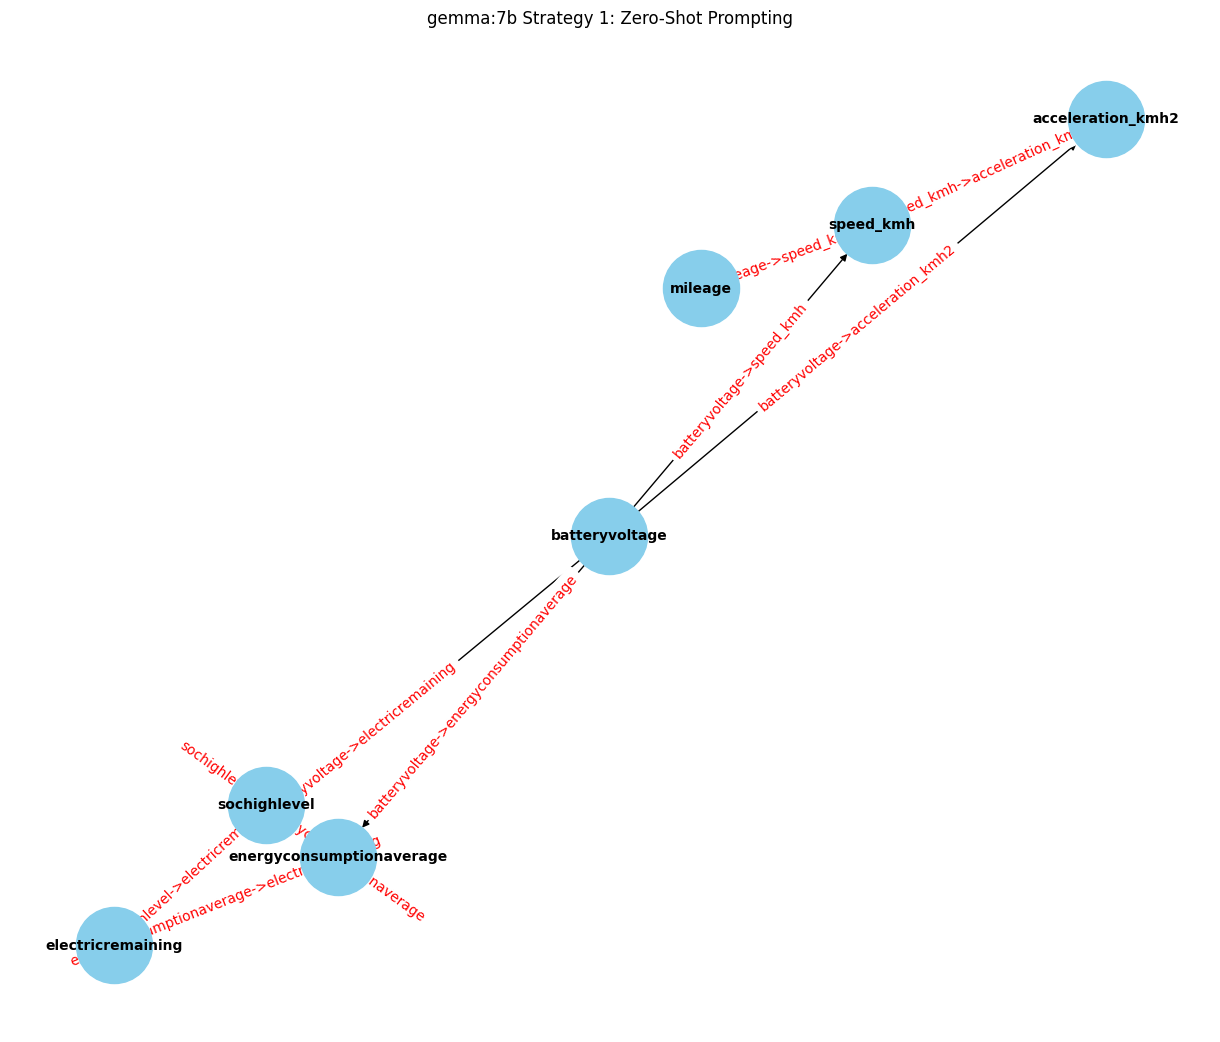

In [27]:
import re
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

strategy_section_name = "Strategy 1: Zero-Shot Prompting"

# Parse causal relationships from the current result
result_text = result if isinstance(result, str) else "\n".join(map(str, result))
relationship_lines = [line.strip() for line in result_text.splitlines() if line.strip()]

causal_relationships = []
for line in relationship_lines:
    normalized_line = line.replace('→', '->')
    if '->' not in normalized_line:
        continue
    cause, effect = [part.strip().replace('*', '') for part in normalized_line.split('->', 1)]
    if cause and effect:
        causal_relationships.append((cause, effect))

# Build causal graph
G = nx.DiGraph()
for cause, effect in causal_relationships:
    G.add_edge(cause, effect)

# Build adjacency matrix using required feature order
features = required_columns if 'required_columns' in globals() else sorted(G.nodes())
adj_matrix = nx.adjacency_matrix(G, nodelist=features).todense()
adj_df = pd.DataFrame(adj_matrix, index=features, columns=features)

print("Adjacency Matrix:")
print(adj_df)

# Save adjacency matrix as .npy named by strategy section
safe_name = re.sub(r'[^A-Za-z0-9]+', '_', strategy_section_name).strip('_')
output_file = f"../results/{MODEL_NAME}_{safe_name}.npy"
np.save(output_file, adj_df.values)
print(f"Saved: {output_file}")

# Plot causal graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color='skyblue',
    font_size=10,
    font_color='black',
    font_weight='bold',
    arrows=True
)

# Add edge labels
edges = [(u, v, {'label': f'{u}->{v}'}) for u, v in G.edges()]
edge_labels = {(u, v): d['label'] for u, v, d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')

plt.title(MODEL_NAME + ' ' + strategy_section_name)
plt.show()

## Strategy 2: Role Prompting


In [41]:
# Role Prompting
prompt = f"""
You are an expert automotive causal AI analyst.
{base_prompt(df, required_columns)}
"""

result = call_ollama(prompt)
print(result)

batteryvoltage -> energyconsumptionaverage
batteryvoltage -> electricremaining
batteryvoltage -> speed_kmh
batteryvoltage -> acceleration_kmh2
sochighlevel -> energyconsumptionaverage
sochighlevel -> electricremaining
energyconsumptionaverage -> electricremaining
mileage -> speed_kmh
speed_kmh -> acceleration_kmh2


Adjacency Matrix:
                          batteryvoltage  sochighlevel  \
batteryvoltage                         0             0   
sochighlevel                           0             0   
energyconsumptionaverage               0             0   
electricremaining                      0             0   
mileage                                0             0   
speed_kmh                              0             0   
acceleration_kmh2                      0             0   

                          energyconsumptionaverage  electricremaining  \
batteryvoltage                                   1                  1   
sochighlevel                                     1                  1   
energyconsumptionaverage                         0                  1   
electricremaining                                0                  0   
mileage                                          0                  0   
speed_kmh                                        0                  0   
accele

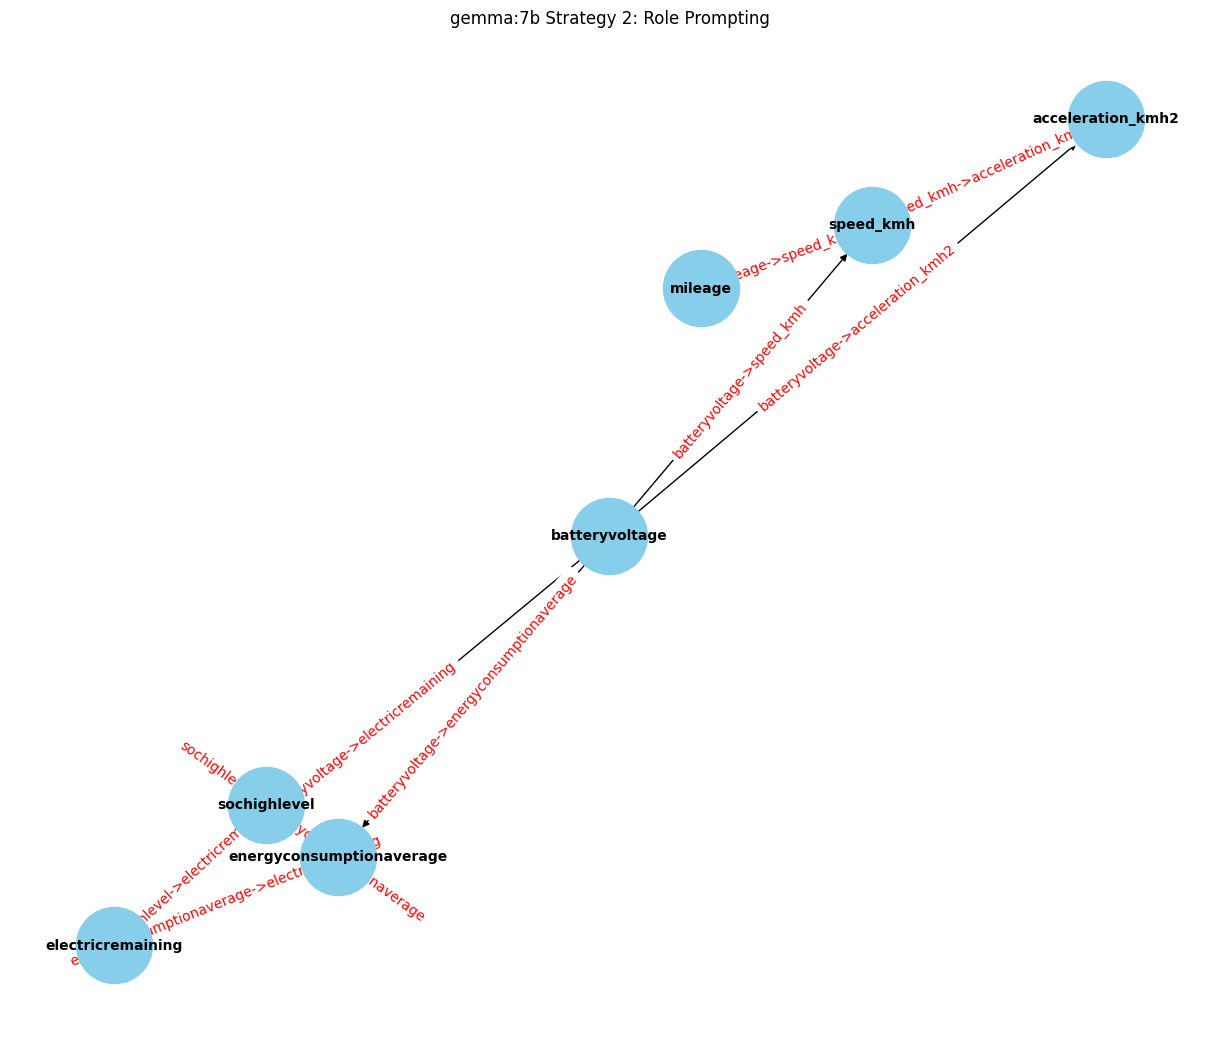

In [42]:
import re
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

strategy_section_name = "Strategy 2: Role Prompting"

# Parse causal relationships from the current result
result_text = result if isinstance(result, str) else "\n".join(map(str, result))
relationship_lines = [line.strip() for line in result_text.splitlines() if line.strip()]

causal_relationships = []
for line in relationship_lines:
    normalized_line = line.replace('→', '->')
    if '->' not in normalized_line:
        continue
    cause, effect = [part.strip().replace('*', '') for part in normalized_line.split('->', 1)]
    if cause and effect:
        causal_relationships.append((cause, effect))

# Build causal graph
G = nx.DiGraph()
for cause, effect in causal_relationships:
    G.add_edge(cause, effect)

# Build adjacency matrix using required feature order
features = required_columns if 'required_columns' in globals() else sorted(G.nodes())
adj_matrix = nx.adjacency_matrix(G, nodelist=features).todense()
adj_df = pd.DataFrame(adj_matrix, index=features, columns=features)

print("Adjacency Matrix:")
print(adj_df)

# Save adjacency matrix as .npy named by strategy section
safe_name = re.sub(r'[^A-Za-z0-9]+', '_', strategy_section_name).strip('_')
output_file = f"../results/{MODEL_NAME}_{safe_name}.npy"
np.save(output_file, adj_df.values)
print(f"Saved: {output_file}")

# Plot causal graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color='skyblue',
    font_size=10,
    font_color='black',
    font_weight='bold',
    arrows=True
)

# Add edge labels
edges = [(u, v, {'label': f'{u}->{v}'}) for u, v in G.edges()]
edge_labels = {(u, v): d['label'] for u, v, d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')

plt.title(MODEL_NAME + ' ' + strategy_section_name)
plt.show()

## Strategy 3: Emotion Prompting


In [67]:
# Emotion Prompting
prompt = f"""
Be extremely precise and careful.
Any wrong causal link could cause system failure.
Only output verified causal discovery.

{base_prompt(df, required_columns)}
"""

result = call_ollama(prompt)
print(result)


batteryvoltage -> energyconsumptionaverage
batteryvoltage -> electricremaining
batteryvoltage -> speed_kmh
batteryvoltage -> acceleration_kmh2
sochighlevel -> energyconsumptionaverage
sochighlevel -> electricremaining
energyconsumptionaverage -> electricremaining
mileage -> speed_kmh
speed_kmh -> acceleration_kmh2


Adjacency Matrix:
                          batteryvoltage  sochighlevel  \
batteryvoltage                         0             0   
sochighlevel                           0             0   
energyconsumptionaverage               0             0   
electricremaining                      0             0   
mileage                                0             0   
speed_kmh                              0             0   
acceleration_kmh2                      0             0   

                          energyconsumptionaverage  electricremaining  \
batteryvoltage                                   1                  1   
sochighlevel                                     1                  1   
energyconsumptionaverage                         0                  1   
electricremaining                                0                  0   
mileage                                          0                  0   
speed_kmh                                        0                  0   
accele

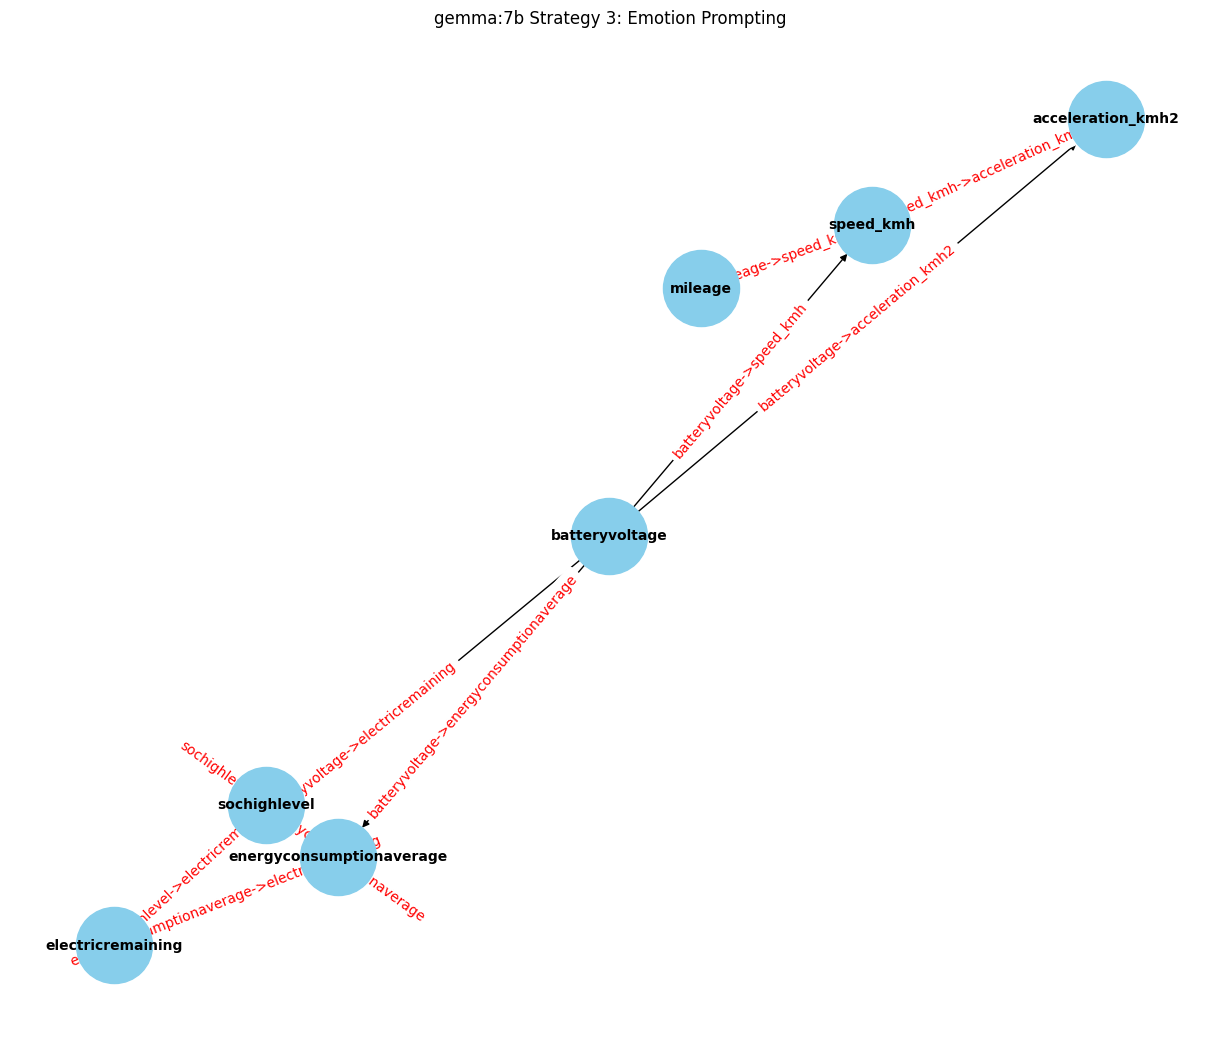

In [68]:
import re
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

strategy_section_name = "Strategy 3: Emotion Prompting"

# Parse causal relationships from the current result
result_text = result if isinstance(result, str) else "\n".join(map(str, result))
relationship_lines = [line.strip() for line in result_text.splitlines() if line.strip()]

causal_relationships = []
for line in relationship_lines:
    normalized_line = line.replace('→', '->')
    if '->' not in normalized_line:
        continue
    cause, effect = [part.strip().replace('*', '') for part in normalized_line.split('->', 1)]
    if cause and effect:
        causal_relationships.append((cause, effect))

# Build causal graph
G = nx.DiGraph()
for cause, effect in causal_relationships:
    G.add_edge(cause, effect)

# Build adjacency matrix using required feature order
features = required_columns if 'required_columns' in globals() else sorted(G.nodes())
adj_matrix = nx.adjacency_matrix(G, nodelist=features).todense()
adj_df = pd.DataFrame(adj_matrix, index=features, columns=features)

print("Adjacency Matrix:")
print(adj_df)

# Save adjacency matrix as .npy named by strategy section
safe_name = re.sub(r'[^A-Za-z0-9]+', '_', strategy_section_name).strip('_')
output_file = f"../results/{MODEL_NAME}_{safe_name}.npy"
np.save(output_file, adj_df.values)
print(f"Saved: {output_file}")

# Plot causal graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color='skyblue',
    font_size=10,
    font_color='black',
    font_weight='bold',
    arrows=True
)

# Add edge labels
edges = [(u, v, {'label': f'{u}->{v}'}) for u, v in G.edges()]
edge_labels = {(u, v): d['label'] for u, v, d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')

plt.title(MODEL_NAME + ' ' + strategy_section_name)
plt.show()

## Strategy 4: Style Prompting


In [102]:
# Style Prompting
prompt = f"""
Respond like a scientific causal discovery engine.
Output minimal, formal arrow notation only.

{base_prompt(df, required_columns)}
"""

result = call_ollama(prompt)
print(result)


batteryvoltage -> energyconsumptionaverage
batteryvoltage -> electricremaining
sochighlevel -> mileage
energyconsumptionaverage -> electricremaining
electricremaining -> mileage
speed_kmh -> energyconsumptionaverage
acceleration_kmh2 -> energyconsumptionaverage


Adjacency Matrix:
                          batteryvoltage  sochighlevel  \
batteryvoltage                         0             0   
sochighlevel                           0             0   
energyconsumptionaverage               0             0   
electricremaining                      0             0   
mileage                                0             0   
speed_kmh                              0             0   
acceleration_kmh2                      0             0   

                          energyconsumptionaverage  electricremaining  \
batteryvoltage                                   1                  1   
sochighlevel                                     0                  0   
energyconsumptionaverage                         0                  1   
electricremaining                                0                  0   
mileage                                          0                  0   
speed_kmh                                        1                  0   
accele

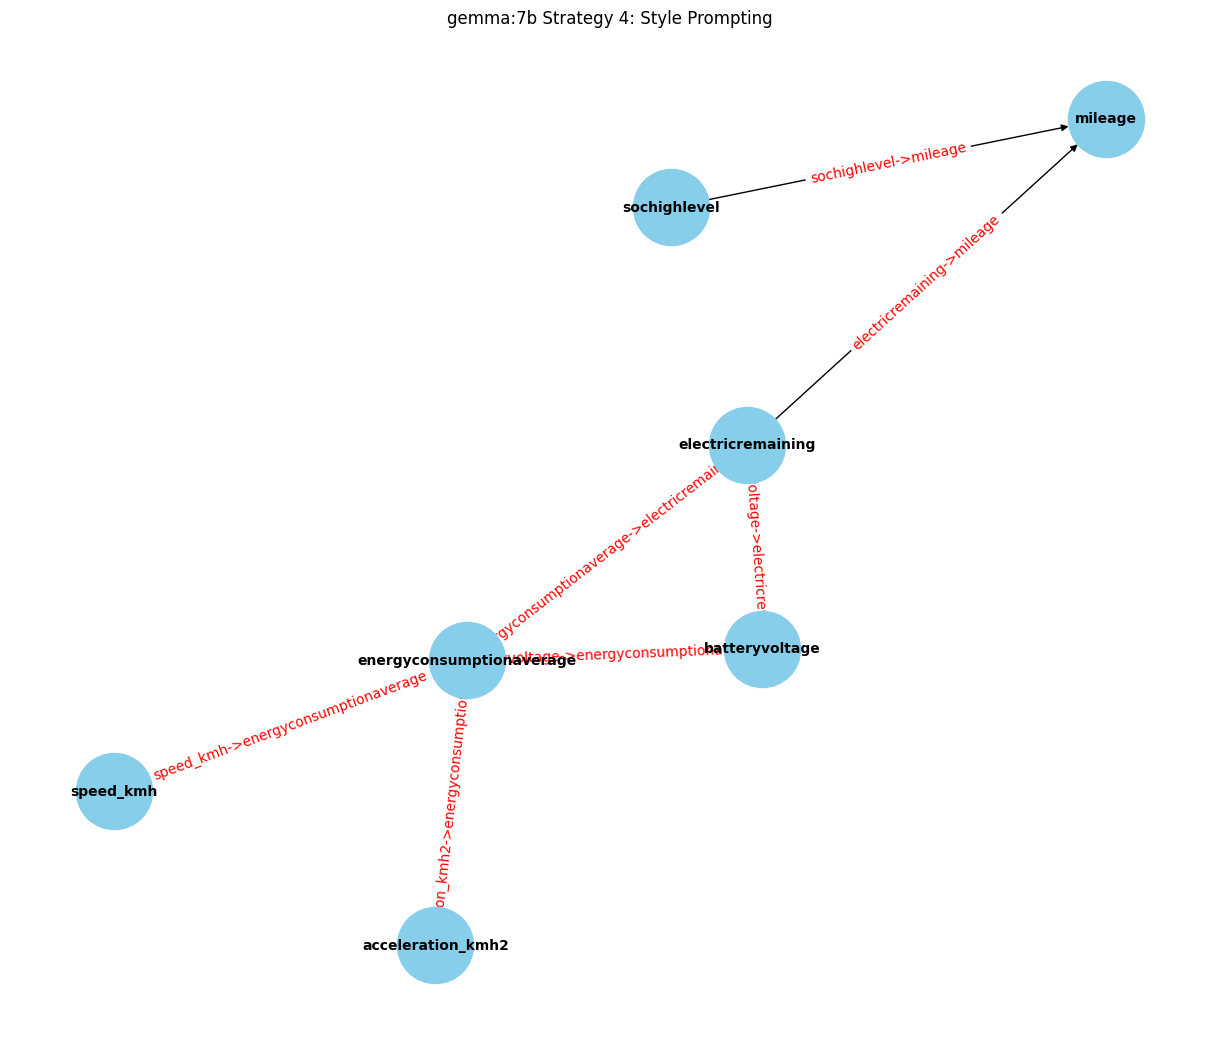

In [103]:
import re
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

strategy_section_name = "Strategy 4: Style Prompting"

# Parse causal relationships from the current result
result_text = result if isinstance(result, str) else "\n".join(map(str, result))
relationship_lines = [line.strip() for line in result_text.splitlines() if line.strip()]

causal_relationships = []
for line in relationship_lines:
    normalized_line = line.replace('→', '->')
    if '->' not in normalized_line:
        continue
    cause, effect = [part.strip().replace('*', '') for part in normalized_line.split('->', 1)]
    if cause and effect:
        causal_relationships.append((cause, effect))

# Build causal graph
G = nx.DiGraph()
for cause, effect in causal_relationships:
    G.add_edge(cause, effect)

# Build adjacency matrix using required feature order
features = required_columns if 'required_columns' in globals() else sorted(G.nodes())
adj_matrix = nx.adjacency_matrix(G, nodelist=features).todense()
adj_df = pd.DataFrame(adj_matrix, index=features, columns=features)

print("Adjacency Matrix:")
print(adj_df)

# Save adjacency matrix as .npy named by strategy section
safe_name = re.sub(r'[^A-Za-z0-9]+', '_', strategy_section_name).strip('_')
output_file = f"../results/{MODEL_NAME}_{safe_name}.npy"
np.save(output_file, adj_df.values)
print(f"Saved: {output_file}")

# Plot causal graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color='skyblue',
    font_size=10,
    font_color='black',
    font_weight='bold',
    arrows=True
)

# Add edge labels
edges = [(u, v, {'label': f'{u}->{v}'}) for u, v in G.edges()]
edge_labels = {(u, v): d['label'] for u, v, d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')

plt.title(MODEL_NAME + ' ' + strategy_section_name)
plt.show()

## Strategy 5: Contextual Prompting


In [130]:
# Contextual Prompting
prompt = f"""
Context:
This dataset is from EV telematics for predictive maintenance.
Causality must reflect physical vehicle dynamics.

{base_prompt(df, required_columns)}
"""

result = call_ollama(prompt)
print(result)


batteryvoltage -> energyconsumptionaverage
batteryvoltage -> electricremaining
sochighlevel -> energyconsumptionaverage
sochighlevel -> electricremaining
energyconsumptionaverage -> electricremaining
mileage -> energyconsumptionaverage
speed_kmh -> energyconsumptionaverage
acceleration_kmh2 -> energyconsumptionaverage


Adjacency Matrix:
                          batteryvoltage  sochighlevel  \
batteryvoltage                         0             0   
sochighlevel                           0             0   
energyconsumptionaverage               0             0   
electricremaining                      0             0   
mileage                                0             0   
speed_kmh                              0             0   
acceleration_kmh2                      0             0   

                          energyconsumptionaverage  electricremaining  \
batteryvoltage                                   1                  1   
sochighlevel                                     1                  1   
energyconsumptionaverage                         0                  1   
electricremaining                                0                  0   
mileage                                          1                  0   
speed_kmh                                        1                  0   
accele

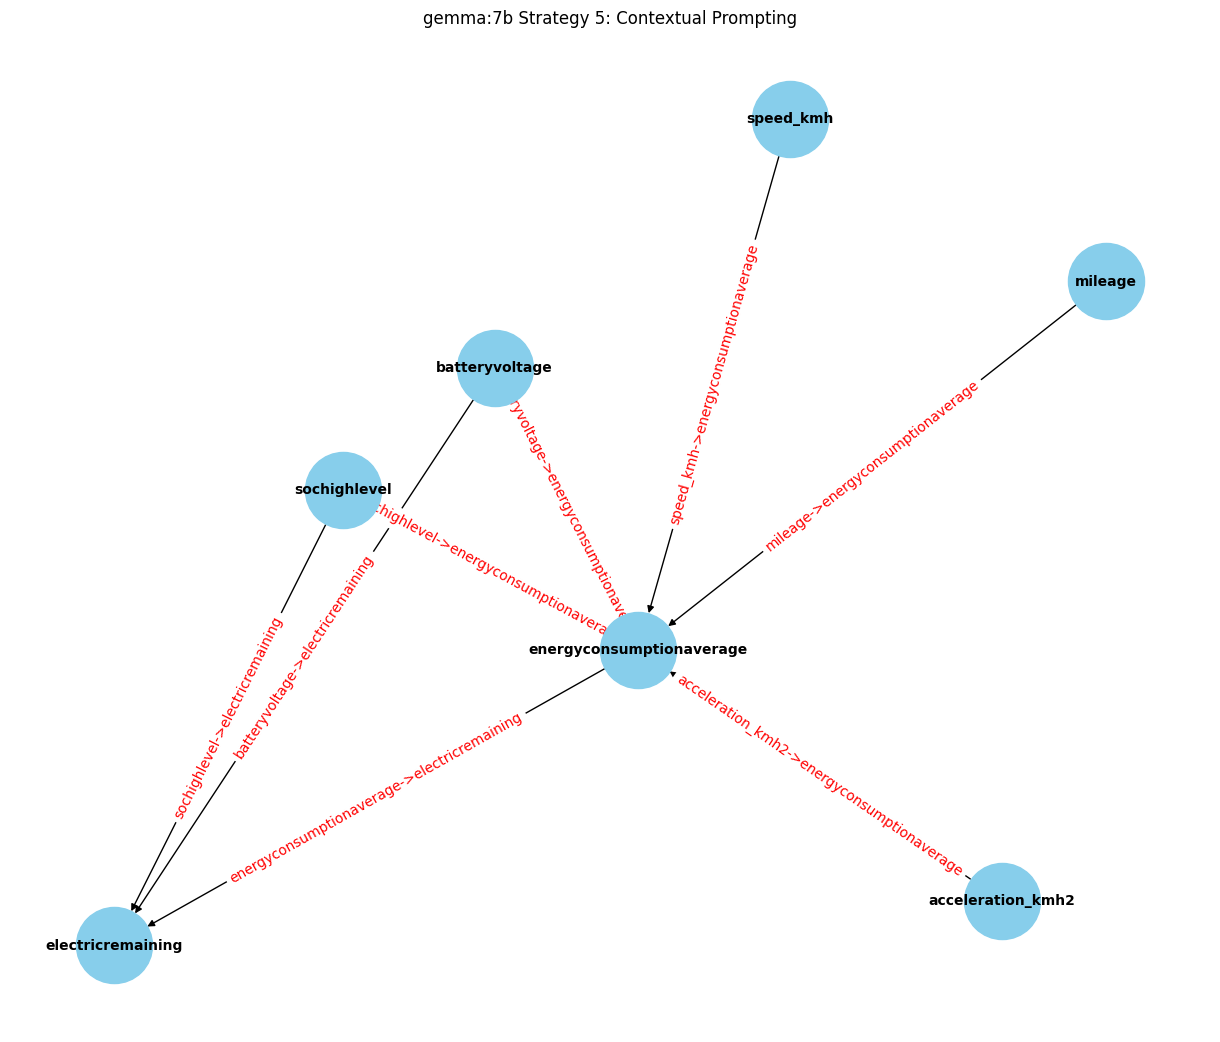

In [131]:
import re
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

strategy_section_name = "Strategy 5: Contextual Prompting"

# Parse causal relationships from the current result
result_text = result if isinstance(result, str) else "\n".join(map(str, result))
relationship_lines = [line.strip() for line in result_text.splitlines() if line.strip()]

causal_relationships = []
for line in relationship_lines:
    normalized_line = line.replace('→', '->')
    if '->' not in normalized_line:
        continue
    cause, effect = [part.strip().replace('*', '') for part in normalized_line.split('->', 1)]
    if cause and effect:
        causal_relationships.append((cause, effect))

# Build causal graph
G = nx.DiGraph()
for cause, effect in causal_relationships:
    G.add_edge(cause, effect)

# Build adjacency matrix using required feature order
features = required_columns if 'required_columns' in globals() else sorted(G.nodes())
adj_matrix = nx.adjacency_matrix(G, nodelist=features).todense()
adj_df = pd.DataFrame(adj_matrix, index=features, columns=features)

print("Adjacency Matrix:")
print(adj_df)

# Save adjacency matrix as .npy named by strategy section
safe_name = re.sub(r'[^A-Za-z0-9]+', '_', strategy_section_name).strip('_')
output_file = f"../results/{MODEL_NAME}_{safe_name}.npy"
np.save(output_file, adj_df.values)
print(f"Saved: {output_file}")

# Plot causal graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color='skyblue',
    font_size=10,
    font_color='black',
    font_weight='bold',
    arrows=True
)

# Add edge labels
edges = [(u, v, {'label': f'{u}->{v}'}) for u, v in G.edges()]
edge_labels = {(u, v): d['label'] for u, v, d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')

plt.title(MODEL_NAME + ' ' + strategy_section_name)
plt.show()